In [24]:
import os
import pandas as pd

# DATA_DIR = "./"

DATA_DIR = "./Agricultural-crops/"  # Apne main folder ka naam yahan likhein

# Sabhi image paths aur unke labels ko ek list me store karenge
image_paths = []
labels = []

crop_folders = [f for f in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, f)) and not f.startswith(('.', 'myenv'))]

for crop in crop_folders:
    crop_path = os.path.join(DATA_DIR, crop)
    for img in os.listdir(crop_path):
        if img.lower().endswith(('.png', '.jpg', '.jpeg')):
            image_paths.append(os.path.join(crop, img))
            labels.append(crop)

# 📊 Ab iska ek badhiya sa Table (DataFrame) banate hain
df = pd.DataFrame({
    'Image_Path': image_paths,
    'Crop_Label': labels
})

# Jaise aap normal CSV check karte hain, waise hi check karein!
print(f"Total Rows (Images) in Dataframe: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\n--- Pehli 5 Rows (df.head) ---")
print(df.head())

Total Rows (Images) in Dataframe: 829
Total Columns: 2

--- Pehli 5 Rows (df.head) ---
              Image_Path Crop_Label
0   almond\image (1).jpg     almond
1   almond\image (1).png     almond
2  almond\image (10).jpg     almond
3  almond\image (11).jpg     almond
4  almond\image (12).jpg     almond


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Image_Path  829 non-null    str  
 1   Crop_Label  829 non-null    str  
dtypes: str(2)
memory usage: 13.1 KB


In [26]:
df.describe()

,Image_Path,Crop_Label
count,829,829
unique,829,30
top,almond\image (1).jpg,Pearl_millet(bajra)
freq,1,39


In [27]:
df.shape

(829, 2)

In [28]:
df.shape[1]

2

In [29]:
df.head()  # First 5 rows
# df.tail()  # Last 5 rows
# df.shape  # Rows, Columns
# df.columns  # Column names
# df.info()  # Data types
# df.describe()  # Numerical statistics

,Image_Path,Crop_Label
0,almond\image (1).jpg,almond
1,almond\image (1).png,almond
2,almond\image (10).jpg,almond
3,almond\image (11).jpg,almond
4,almond\image (12).jpg,almond


In [30]:
df.columns

Index(['Image_Path', 'Crop_Label'], dtype='str')

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Image_Path  829 non-null    str  
 1   Crop_Label  829 non-null    str  
dtypes: str(2)
memory usage: 13.1 KB


In [32]:
df.isnull().sum()

Image_Path    0
Crop_Label    0
dtype: int64

In [33]:
df.shape

(829, 2)

2. Number of Crop Classes

df["Crop_Label"].nunique()

In [34]:
df["Crop_Label"].nunique()

30

3. Class Distribution

<Axes: xlabel='Crop_Label'>

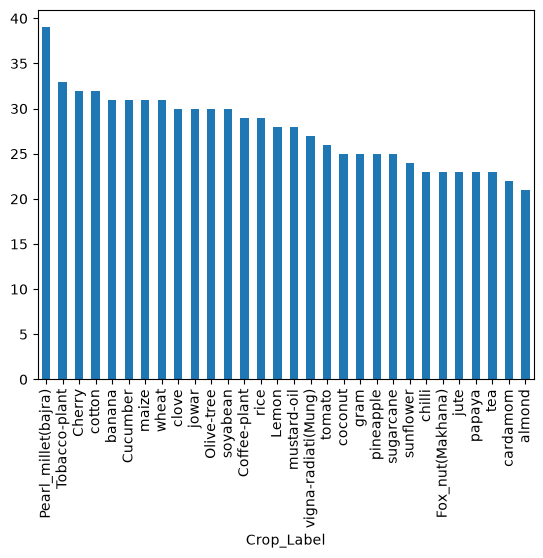

In [40]:
#
df["Crop_Label"].value_counts().plot(kind="bar")

Step 2: Class Distribution

Check karo ki sabhi classes me kitni images hain.

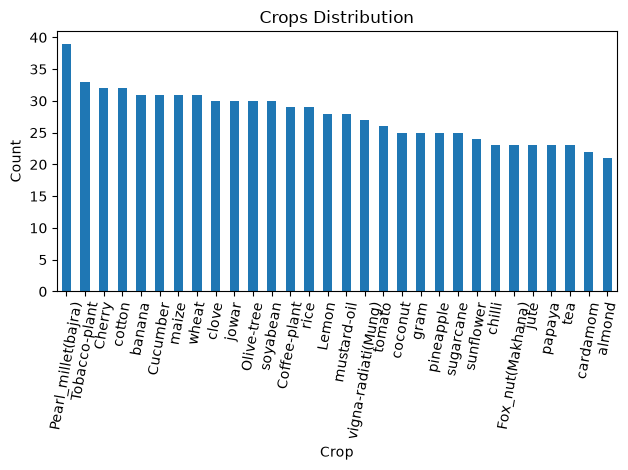

In [39]:
import matplotlib.pyplot as plt 
df["Crop_Label"].value_counts().plot(kind="bar")
plt.title("Crops Distribution")
plt.xlabel("Crop")
plt.ylabel("Count")
plt.xticks(rotation=80)
plt.tight_layout()
plt.show()

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
import os

df["Image_Path"].apply(os.path.exists).value_counts()

Image_Path
False    829
Name: count, dtype: int64

In [43]:
df["Image_Path"].head()

0     almond\image (1).jpg
1     almond\image (1).png
2    almond\image (10).jpg
3    almond\image (11).jpg
4    almond\image (12).jpg
Name: Image_Path, dtype: str

In [44]:
import os

print(os.getcwd())

d:\mlprojects\crop-pridiction-system


In [45]:
import os

print(df.loc[0, "Image_Path"])
print(os.path.exists(df.loc[0, "Image_Path"]))

almond\image (1).jpg
False


In [46]:
import os

print(os.getcwd())

d:\mlprojects\crop-pridiction-system


In [47]:
import os

base_path = r"D:\mlprojects\crop-pridiction-system\Agricultural-crops"

df["Image_Path"] = df["Image_Path"].apply(lambda x: os.path.join(base_path, x))

print(df["Image_Path"].head())
print(df["Image_Path"].apply(os.path.exists).value_counts())

0    D:\mlprojects\crop-pridiction-system\Agricultu...
1    D:\mlprojects\crop-pridiction-system\Agricultu...
2    D:\mlprojects\crop-pridiction-system\Agricultu...
3    D:\mlprojects\crop-pridiction-system\Agricultu...
4    D:\mlprojects\crop-pridiction-system\Agricultu...
Name: Image_Path, dtype: str
Image_Path
True    829
Name: count, dtype: int64


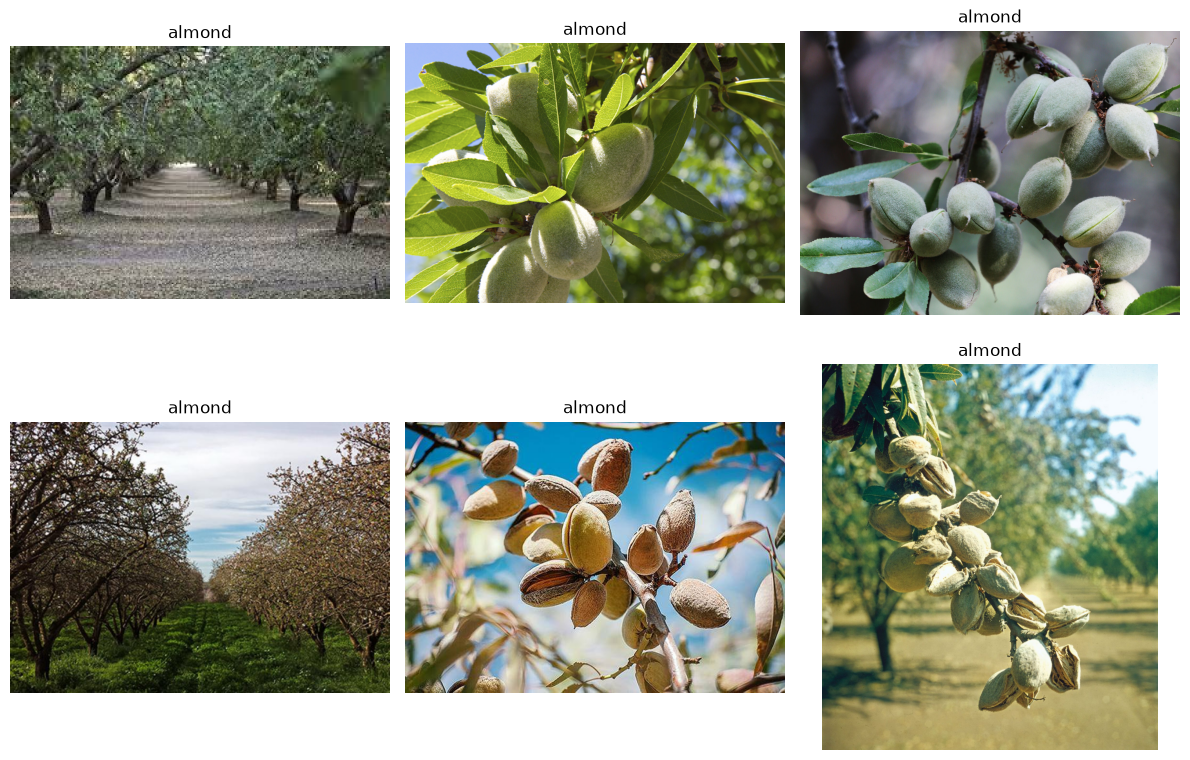

In [48]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for i in range(6):
    plt.subplot(2, 3, i + 1)

    img = Image.open(df.loc[i, "Image_Path"])
    plt.imshow(img)
    plt.title(df.loc[i, "Crop_Label"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [49]:
from PIL import Image

img = Image.open(df.loc[0, "Image_Path"])

print(img.size)
print(img.mode)

(275, 183)
RGB


In [50]:
print(img.mode)


RGB


Ab agla step: Image Resize aur Normalize

TensorFlow/Keras ka use kar rahe ho to ye code use karo

In [51]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

image = load_img(df.loc[0, "Image_Path"], target_size=(224, 224))

image = img_to_array(image)

image = image / 255.0

print(image.shape)

(224, 224, 3)


In [52]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [53]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np

X = []
y = []

for i in range(len(df)):

    img = load_img(df.loc[i, "Image_Path"], target_size=(224, 224))

    img = img_to_array(img)

    img = img / 255.0

    X.append(img)

    y.append(df.loc[i, "Crop_Label"])

In [54]:
X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(829, 224, 224, 3)
(829,)


In [56]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print(encoder.classes_)
print(y[:10])

['Cherry' 'Coffee-plant' 'Cucumber' 'Fox_nut(Makhana)' 'Lemon'
 'Olive-tree' 'Pearl_millet(bajra)' 'Tobacco-plant' 'almond' 'banana'
 'cardamom' 'chilli' 'clove' 'coconut' 'cotton' 'gram' 'jowar' 'jute'
 'maize' 'mustard-oil' 'papaya' 'pineapple' 'rice' 'soyabean' 'sugarcane'
 'sunflower' 'tea' 'tomato' 'vigna-radiati(Mung)' 'wheat']
[8 8 8 8 8 8 8 8 8 8]


In [ ]:
# Step 4: Train-Test Split

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [58]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(663, 224, 224, 3)
(166, 224, 224, 3)
(663,)
(166,)


<!-- Step 5: CNN Model -->

In [59]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", input_shape=(224, 224, 3)),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(128, activation="relu"),
        Dense(len(encoder.classes_), activation="softmax"),
    ]
)

model.summary()

d:\mlprojects\crop-pridiction-system\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 30)             │         3,870 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,911,262 (91.21 MB)

 Trainable params: 23,911,262 (91.21 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [ ]:
history = model.fit(
    X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=32
)

Epoch 1/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - accuracy: 0.0483 - loss: 7.2389 - val_accuracy: 0.0301 - val_loss: 3.3916
Epoch 2/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.0649 - loss: 3.3623 - val_accuracy: 0.0904 - val_loss: 3.2903
Epoch 3/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.2097 - loss: 2.9697 - val_accuracy: 0.1265 - val_loss: 2.9708
Epoch 4/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.4917 - loss: 2.0153 - val_accuracy: 0.1988 - val_loss: 3.0891
Epoch 5/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 52s 2s/step - accuracy: 0.7843 - loss: 1.0118 - val_accuracy: 0.2289 - val_loss: 3.2792
Epoch 6/10
21/21 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9186 - loss: 0.4304 - val_accuracy: 0.2289 - val_loss: 3.0223
Epoch 7/10
 1/21 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.9688 - loss: 0.1848